Name: Emily Savoie

Labpartner(s): Maru Shapiro

In [1]:
#import statements go here
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Class 8.2

Today we are having a guest lecture online by [Will Faulkner](https://www.linkedin.com/in/wnfaulkner/) on "vibe coding" aka the use of LLMs to build code when you have no or little idea what you are doing. 

**W.1** This week our warmups are focused on applying your Pandas skills. Please continue your analysis of the 2026 World Cup player stats from slack (pinned to #announcements). Make sure you write some text about what you found. 

In [2]:
soccer = pd.read_csv('player_stats.csv', index_col = 0)
soccer

,player_name,team_id,position,matches_played,matches_started,minutes_played,goals,assists,shots,shots_on_target,yellow_cards,red_cards,penalty_goals,own_goals,clean_sheets,saves,goals_conceded,average_rating,data_source,last_verified
player_id,,,,,,,,,,,,,,,,,,,,
1,José Raúl Rangel,1,GK,5,5,438,0,0,NaN,NaN,0,0,0,0,4.0,7.0,3.0,NaN,sofascore.com,2026-07-19
2,Jorge Eduardo Sanchez,1,DEF,5,5,439,0,1,NaN,NaN,0,0,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19
3,César Jasib Montes,1,DEF,3,2,165,0,0,NaN,NaN,0,1,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19
4,Edson Omar Alvarez,1,DEF,2,0,75,0,0,NaN,NaN,1,0,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19
5,Johan Felipe Vasquez,1,DEF,2,2,180,0,0,NaN,NaN,0,0,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1244,Orlando Mosquera,48,GK,3,3,270,0,0,NaN,NaN,0,0,0,0,0.0,8.0,4.0,NaN,sofascore.com,2026-07-19
1245,Michael Amir Murillo,48,DEF,3,3,270,0,0,NaN,NaN,0,0,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19
1246,Azarías Emmanuel Londono,48,FWD,3,0,53,0,0,NaN,NaN,0,0,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19


In [ ]:
# Get overview of data
soccer.describe()

,team_id,matches_played,matches_started,minutes_played,goals,assists,shots,shots_on_target,yellow_cards,red_cards,penalty_goals,own_goals,clean_sheets,saves,goals_conceded,average_rating
count,1248.000000,1248.000000,1248.000000,1248.000000,1248.000000,1248.000000,0.0,0.0,1248.000000,1248.000000,1248.0,1248.000000,145.00000,145.000000,145.000000,0.0
mean,24.500000,2.564103,1.833333,168.997596,0.235577,0.163462,NaN,NaN,0.028045,0.009615,0.0,0.011218,0.37931,4.772414,2.165517,NaN
std,13.858953,1.782673,1.771496,152.687113,0.766552,0.540763,NaN,NaN,0.165167,0.097625,0.0,0.112716,0.85040,6.674729,2.908354,NaN
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,0.000000,0.000000,0.0,0.000000,0.00000,0.000000,0.000000,NaN
25%,12.750000,1.000000,0.000000,23.000000,0.000000,0.000000,NaN,NaN,0.000000,0.000000,0.0,0.000000,0.00000,0.000000,0.000000,NaN
50%,24.500000,3.000000,2.000000,146.000000,0.000000,0.000000,NaN,NaN,0.000000,0.000000,0.0,0.000000,0.00000,0.000000,0.000000,NaN
75%,36.250000,4.000000,3.000000,270.000000,0.000000,0.000000,NaN,NaN,0.000000,0.000000,0.0,0.000000,0.00000,8.000000,4.000000,NaN
max,48.000000,8.000000,8.000000,750.000000,10.000000,8.000000,NaN,NaN,1.000000,1.000000,0.0,2.000000,5.00000,29.000000,10.000000,NaN


In [ ]:
# Look at cards by position
soccer.groupby('position')[['yellow_cards', 'red_cards']].sum()

,yellow_cards,red_cards
position,,
DEF,15,7
FWD,5,1
GK,0,0
MID,15,4


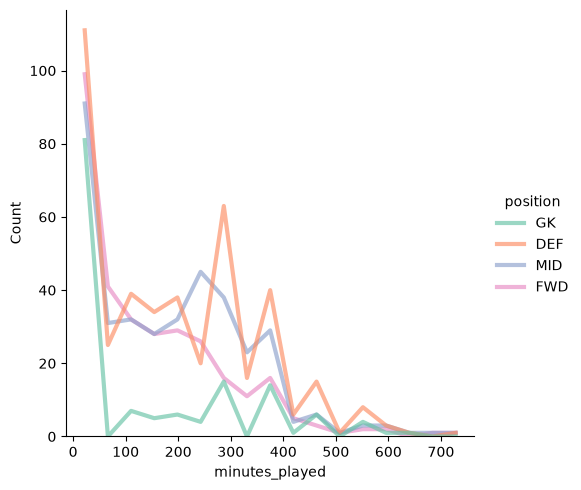

In [ ]:
# Histogram with unfilled polygons of minutes played by position
sns.displot(data = soccer, x = 'minutes_played', hue = 'position', element = 'poly', 
            alpha = 0.65, palette = 'Set2', fill = False, linewidth = 3)
plt.show()

In [ ]:
# Creation of dataframe of total yellow and red cards given by position
cards_position = soccer.groupby('position')[['yellow_cards','red_cards']].sum()
cards_position

,yellow_cards,red_cards
position,,
DEF,15,7
FWD,5,1
GK,0,0
MID,15,4


<Axes: xlabel='position'>

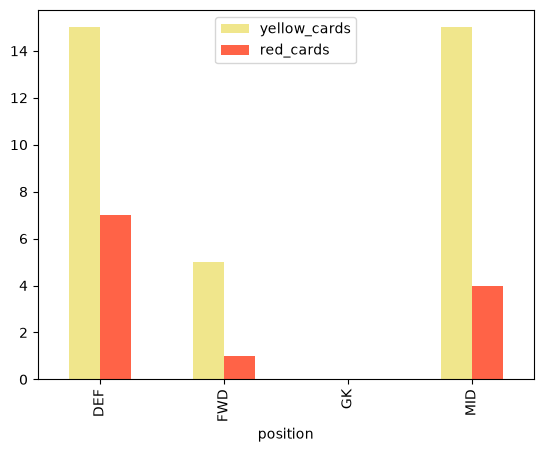

In [ ]:
# Bar plot of total cards given to each position
cards_position.plot(kind = 'bar', color = ['khaki', 'tomato'])

Defenders seem to play more mintues per player than other positions. Defenders also account for the most total cards given. 

# Lecture 8.2

### Agenda: Will will talk about vibe coding, we'll have a break, and then he'll share some examples


### Questions

# Lab 8.2

**E.0** Complete the previous labs if you are behind.

**E.1** "Vibe coding" in practice, part 1. Take a dataset of your choice and use an LLM to do some kind of manipulation or analysis of that data. You should focus on trying something that you couldn't easily figure out on your own. Paste the resulting code and results here.

I went with getting Claude to do a multivariate regression analysis as closely as it could to an unsupported R package. I provided two data files from the EPA and provided the following prompt:  

I have these two files I am working with. I want to take the environmental values from one (from bulk density on) and use the community matrix in the other to perform a multivariate regression in as similar a way as is possible to the R package mvpart in python. I do not want to drop rare taxa (I will make that decision later). I do not want unnecessary data manipulation. Provide the code output to perform this task in python with code comments for what is being accomplished at each step. I want to be able to perform this on my own later. Explain what the format goals are, input requirements, etc. as is needed in the code.  

I got it to return the code in a Jupyter notebook linked [here](mrt_benthic.ipynb)

**E.2** "Vibe coding" in practice, part 2. Now take the same data set and make some kind of plot, again focusing on something that would be difficult to figure out on your own. Paste the resulting code and results here.

I ended up doing two different graph types which can be found in two different notebooks. 

First, I generated a cleaner tree output from the multivariate regression. The code can be found [here](mrt_tree_dendrogram.ipynb). This was done with the following prompt:  
I would like a visually pleasing output for the multivariate regression. Create a separate Jupyter notebook that adjusts the tree output to be a high quality figure that would remain visually appealing and readable if there were more branches and nodes. I want the font to be readable, color blind friendly palette (i.e., Set2) and concise legends when needed. I'd like the tree output to be similar to a dendrogram.  

Second, I generated a ridgeline plot of the species richness and shannon diversity. The code can be found [here](ridgeline_richness_shannon_seaborn.ipynb). This was done with the following prompt:  
Next I want to create a ridgeline plot with this data. I want two plots generated in one figure. One to be species richness across sites, the other shannon diversity. I want to indicate a grouping based on the upper, middle, or lower designation of each site.  I want this to be output in a Jupyter notebook and to have the same type of comments as the previous code: explaining what the code is doing, format/input requirements, etc.

**E.3** Now let's think, does your use of AI in the examples above fit into Wiley's best practices framework? What are the dangers and oppertunities here? Use specific examples from the Wiley resources and relate them to your workflow above:

https://www.wiley.com/en-us/publishing/book/ai-guidelines

https://www.wiley.com/en-us/publishing/article/ai-guidelines

Specifically, when is it ethical to use AI for research, and when is it not? When is it in your best interest as a student to use AI, and when is it not? What are the enviornmental considerations of using AI? How might you use AI in your final project in line with ethical guidelines? You should be writng a few paragraphs at minimum with examples here. 


 At this stage, I think the AI use is still within the ethical guidelines from Wiley. To start with, it's a publicly available published dataset. This removes the potential for sharing data and accidentally giving rights to the AI for the data. Since this was pulled directly from the EPA's website, it could have been fetched by the AI itself via a prompt to scrap the internet for it. If the input was my own data, I'd be more concerned. I do not have a paid account with Claude, so I have minimal controls over privacy settings. I did turn off the training setting and as far as I am aware, Claude doesn't claim ownership over the outputs. However, I'd be worried about security issues surrounding unpublished data, since I'm not sure how Claude stores any input data. Looking at Wiley's suggestion terms to check for does not have any hits with Claude's terms of service. This makes me feel better about saying that generally, using Claude follows their guidelines. For the first portion of this, I would have to have an expert vet the analysis being done for the multivariate regression. I have a basic stats understanding, but my expertise is not high enough to validate the stats performed for the regression analysis. In the current state, and with just my review, I don't think providing this to the public would fall under Wiley's ethical guidelines. 

The dangers feel obvious to me. It is an easy trap to fall into of getting AI to do work that you don't understand. I feel my use of the multivariate regression would be an excellent example. Like I said, I have a basic stats knowledge base and some familiarity, but I don't have the understanding to currently validate all of the steps used to produce that regression analysis. Where I go from this step is the difference between danger and opporunity in my mind. Blindly trusting it and using it with my own data without getting people with more stats knowledge to look it over can easily result it incorrect data interpertation or misguided claims and an inability to defend those statements. Going over the output with an expert, making adjustmests where needed, and ensuring that the stats are correct for the analysis being done is an excellent opporotunity that could provide a methodology for analysis that is very useful for my work but increasingly difficult to do as the R package has no support and is difficult to get to run. AI can be a powerful tool to assist in learning or cutting down time for tasks. It is important to be sure that you're able to defend any of the outputs though.

I think ethical use of AI in research is using it for time consuming tasks that are easy to vet for mistakes. If you have a large code script that you've worked on, using AI to locate and identify the cause of a bug is useful and not unethical in my opinion. Getting AI to reveiw a document you wrote and provide potential counterarguments can help you pinpoint potential holes in your logic or project and I do not find to be untheical. I do think it is unethical to make AI draw conclusions for you with no validation or understanding of those conclusions. I thimk it's unethical to rely on decisions made by AI. Science requires expertise and collaboration. Especially as students, relying on AI for critical thinking skills around understanding your data and decision making skills of your field is a diservice to yourself. It limits your ability to learn and can lead to a person being a professional in a field that they have no true grasp on. For the final project in this class, my potential AI use, within Wiley's ethical guidelines, would be  suggestions for workflows based on the type of data and end goals and probable debugging assistance. 

**E.4** Make notes for yourself on progamming tecniques and commands you learned in the this week, including examples, comments and explainitory text. You can do this here or in a separate notebook that you link to here. Basically, you are making a cheat sheet for yourself.

[Reference Notebook](Reference_notebook.ipynb)